# Before You Start — What This Course Assumes

This course takes some machine learning as known: how to run an experiment whose score can be trusted, how a neural network learns, and how text becomes numbers that a network reads in order, up to recurrent networks such as the LSTM. Wherever you learned it, this notebook goes over it in one sitting, so you can check that it is familiar and fill any gaps. It is optional and comes before Session 0.

It ends where the LSTM runs out of room, on a task we measure, and with **attention**, which solves that task. Attention is not assumed: it is the idea Session 1 opens up inside GPT-2, so this notebook introduces it from the start.

**By the end you should be able to:**

1. run and read an honest experiment: split, baseline, fit, evaluate once, and read the errors;
2. write the training loop of a small PyTorch network and read its loss curves;
3. explain how text becomes token ids and vectors, and why an LSTM's memory of fixed size limits what it can recall;
4. say what a query, a key and a value do in attention, and why attention can recall what the LSTM loses.

It takes about 60 minutes. **To run it yourself** you need `numpy`, `pandas`, `matplotlib`, `scikit-learn` and `torch`, and nothing is downloaded. The saved outputs came from a laptop GPU, where the whole notebook ran in about two minutes. On a CPU the training in sections 11 to 13 takes about ten minutes. Every output is saved, so you can also read it without running anything. Most numbers come from the cells below. The others come from experiments in the basic AI Journey course, which teaches this material; they are marked *basic course* with the session they come from.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # lets the GPU repeat a run exactly
import math, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from torch import nn
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
from aij_common import DEVICE, set_seed
torch.use_deterministic_algorithms(True)
print("device:", DEVICE)

device: cuda


---

# Part 1 — An experiment you can trust

## 1. Five steps

An experiment follows the same chain every time: **split** the data and put the test set away, set a **baseline**, **fit** a model on the training set, **evaluate** it on the test set, and **read the errors**.

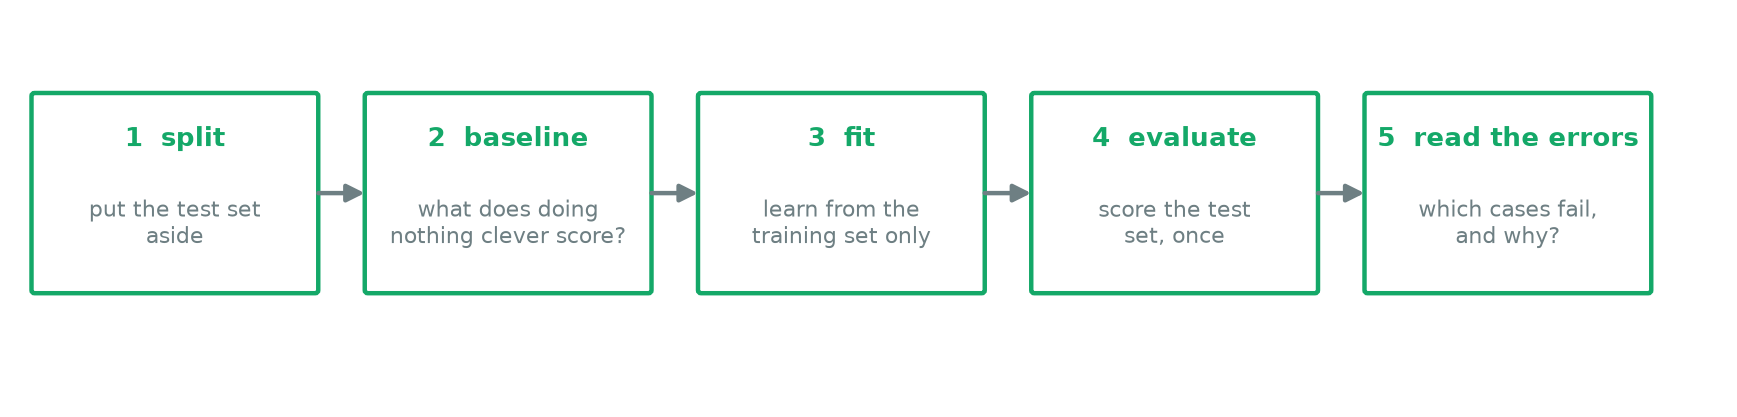

*Figure P.1 — The five steps of an experiment (from the basic course, Session 0).*

We run all five on the breast-cancer data that comes with scikit-learn: 569 tumours, each described by 30 measurements and labelled malignant or benign. Malignant is the **positive** class, the one we want to find. A quarter of the rows are held out as the test set. `stratify` keeps the share of malignant tumours the same in both parts.

In [2]:
data = load_breast_cancer()
X, y = data.data, (data.target == 0).astype(int)                  # 1 = malignant, 0 = benign
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)          # always answers "benign"
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
tn, fp, fn, tp = confusion_matrix(y_test, model.predict(X_test)).ravel()

print(f"{len(X_train)} training tumours, {len(X_test)} test tumours ({y_test.sum()} malignant)")
print(f"baseline:            test accuracy {baseline.score(X_test, y_test):.3f}")
print(f"logistic regression: test accuracy {model.score(X_test, y_test):.3f}   training accuracy {model.score(X_train, y_train):.3f}")
print(f"malignant found: {tp} of {tp + fn} (recall {tp / (tp + fn):.3f});  benign called malignant: {fp} (precision {tp / (tp + fp):.3f})")

426 training tumours, 143 test tumours (53 malignant)
baseline:            test accuracy 0.629
logistic regression: test accuracy 0.986   training accuracy 0.993
malignant found: 51 of 53 (recall 0.962);  benign called malignant: 0 (precision 1.000)


The baseline, which always answers "benign", scores 0.629: that is the share of benign tumours in the test set. The model scores 0.986 on the test set and 0.993 on the training set. A small gap like this is normal, because the model has seen the training tumours.

**Reading the errors:** it found 51 of the 53 malignant tumours and called no benign tumour malignant. Both of its mistakes are malignant tumours called benign, the costly kind for this problem, and the accuracy alone doesn't show that. Compare with what a person could do, too: on 38 iris flowers, a two-line rule written by hand scored 0.947 and a fitted model 0.921 (basic course, Session 0). A model is worth keeping only if it beats the simplest thing that works.

## 2. Data before models: preprocessing and leakage

Much of the work happens before any model is fitted.

- **Read the table first.** Look for duplicate rows, missing values, impossible values (an attendance of 140%) and the balance of the target column. A model learns from all of it without complaint.
- **Fit every preprocessing step on the training rows only.** The scaler above learned its means and spreads from the training tumours. If it had seen the test rows, the test score would no longer be a score on unseen data. Putting the steps in one `Pipeline` with the model makes this automatic.
- **Ask of every feature: would it be known when the prediction is made?** In a table of students, a `certificate_issued` column, filled in after the results were known, took a pipeline from 0.832 to a perfect 1.000 (basic course, Session 2). Nothing in the code was wrong. The column was the answer under another name. This is **leakage**.
- **One split is one draw.** Another random split gives a different score. **Cross-validation** fits the model five times, each time holding out a different fifth of the training rows, and shows how far the score moves.

In [3]:
folds = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X_train, y_train, cv=5)
print("accuracy on each of the five folds:", folds.round(3))
print(f"mean {folds.mean():.3f}, standard deviation {folds.std():.3f}")

accuracy on each of the five folds: [0.977 0.976 0.965 1.    0.988]
mean 0.981, standard deviation 0.012

The five folds score from 0.965 to 1.000, with a mean of 0.981 and a standard deviation of 0.012. Each fold holds about 85 tumours, so one tumour moves its score by more than a point. The single test score, 0.986, falls inside that range. A difference between two models that is smaller than this spread is not evidence that one of them is better.

## 3. Models and overfitting

Each kind of model has its own **inductive bias**, a built-in preference for a kind of answer: logistic regression draws a straight boundary, k-nearest neighbours copies the labels of nearby points, a decision tree asks yes/no questions about one feature at a time, and a random forest averages many trees. On two curved "moons", logistic regression scored 0.852 and the other three 0.910 to 0.919 (basic course, Session 3).

A flexible model can also **overfit**. Here is the classic case: decision trees of depth 1 to 15 on 600 noisy moon-shaped points, 210 of them held out.

> **Pause:** as the tree gets deeper, its training accuracy climbs towards 1.000. What does its test accuracy do?
>
> - **A.** It climbs too, a little more slowly.
> - **B.** It peaks at a small depth, then stays at or below that peak.
> - **C.** It collapses once the tree starts memorising points.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**B.** Test accuracy peaks at 0.886 at depth 6 and is 0.881 at depth 15, while training accuracy reaches 1.000.

</details>

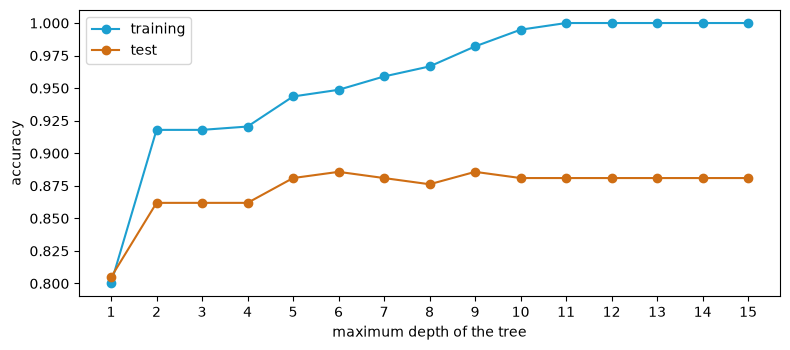

test accuracy peaks at 0.886 (depth 6);  training accuracy first reaches 1.000 at depth 11;  depth 15: training 1.000, test 0.881


In [4]:
# Figure P.2: training and test accuracy of decision trees of depth 1 to 15
X_m, y_m = make_moons(n_samples=600, noise=0.3, random_state=0)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(X_m, y_m, test_size=0.35, random_state=0)
depths = list(range(1, 16))
trees = [DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xm_train, ym_train) for d in depths]
train_acc = [t.score(Xm_train, ym_train) for t in trees]
test_acc = [t.score(Xm_test, ym_test) for t in trees]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(depths, train_acc, "o-", color="#1C9FD0", label="training")
ax.plot(depths, test_acc, "o-", color="#CF6E14", label="test")
ax.set(xlabel="maximum depth of the tree", ylabel="accuracy", xticks=depths)
ax.legend(); plt.tight_layout(); plt.show()
best = int(np.argmax(test_acc))
print(f"test accuracy peaks at {test_acc[best]:.3f} (depth {depths[best]});  training accuracy first reaches 1.000 at depth {depths[train_acc.index(1.0)]};  "
      f"depth 15: training {train_acc[-1]:.3f}, test {test_acc[-1]:.3f}")

*Figure P.2 — Training and test accuracy of decision trees of depth 1 to 15 on the same 600 moon-shaped points. Training accuracy climbs to 1.000; test accuracy stops improving after a few levels.*

Training accuracy climbs until the tree has a region for every training point: 1.000 from depth 11. Test accuracy stops improving long before that. It peaks at 0.886 at depth 6 (and again at depth 9) and is 0.881 at depth 15. The gap of 12 points between the two is **overfitting**: the deep tree has learned the noise in its training points, so its training score no longer says anything about new data. On a different draw of moons the basic course (Session 3) found a gap of 11 points.

## 4. When is a score good?

A fraud detector can score 99.1% on 5,000 transactions and be useless: a rule that always says "no fraud" scored 99.0%, and the model found 5 of the 50 frauds (basic course, Session 4). When one class is rare, accuracy is dominated by the common class. Look at the two kinds of mistake separately:

- **recall** is the share of real positives the model finds (0.962 in section 1: 51 of 53 in section 1);
- **precision** is the share of its positive answers that are right (1.000 in section 1: no false alarms in section 1).

Which one matters more is a decision about costs, not a fact about the model. A model that outputs a probability can trade one for the other by moving its **threshold**. The order that keeps the final score honest:

1. **tune** the model's settings with cross-validation on the training set;
2. **choose the threshold** on a separate **validation set**, from a policy written down before looking;
3. **lock** everything;
4. **score the test set once**, and report the result as it is.

Looking at the test set to make any decision turns it into a second validation set, and its score is no longer an estimate for new data. This course applies the same discipline to language models: Session 10 puts an interval on every benchmark score, and Session 11 measures how much a lucky run inflates the best of several.

## 5. Without labels

**Unsupervised learning** looks for structure in data without answers. **k-means** places K centres, assigns each point to the nearest, moves each centre to the mean of its points, and repeats. On four generated groups it finds them almost exactly (adjusted Rand index 0.996, silhouette 0.757), and the clusters change when one feature's units change, because "near" depends on scale. **PCA** flattens many features into a few directions of largest spread: two directions keep 21.6% of the variance of 8×8 digit images (basic course, Session 5). The same kind of flat map is used whenever vectors with dozens or hundreds of numbers need to be looked at, as with the word vectors in section 10.

---

# Part 2 — Neural networks

## 6. One unit, then layers, then the training loop

A **unit** (or neuron) multiplies its inputs by weights, adds a bias, and passes the result through a function. With a sigmoid at the end it is logistic regression, and its boundary is a straight line. A straight line can't do **XOR**, where the answer is 1 when exactly one of two inputs is 1. Stacking units in **layers**, with a non-linear **activation** such as `tanh` or `ReLU` after each hidden layer, lets the hidden units build new features from which the output can decide. Without the activation, two layers collapse into one straight line.

Training is one loop, which scikit-learn hides inside `fit`:

1. run the examples through the network and compute the **loss**, one number for how wrong it is;
2. compute the **gradient**: how the loss changes with each weight. **Backpropagation** does this for every weight in every layer; in PyTorch it is `loss.backward()`;
3. move every weight a small step against its gradient. The **learning rate** sets the step size, and the **optimiser** (here Adam, the usual default) takes the step.

The network below has two inputs, four `tanh` units and one output.

In [5]:
set_seed(0)
X_xor = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_xor = torch.tensor([[0.], [1.], [1.], [0.]])
net = nn.Sequential(nn.Linear(2, 4), nn.Tanh(), nn.Linear(4, 1))     # the output is a score; sigmoid(score) is the probability
loss_fn = nn.BCEWithLogitsLoss()                                     # sigmoid and cross-entropy in one step
optimizer = torch.optim.Adam(net.parameters(), lr=0.05)
print("parameters:", sum(p.numel() for p in net.parameters()))

for epoch in range(1, 501):
    loss = loss_fn(net(X_xor), y_xor)       # 1. how wrong
    optimizer.zero_grad()                   #    (clear the previous step's gradients)
    loss.backward()                         # 2. the gradient for every weight
    optimizer.step()                        # 3. a small step against it
    if epoch in (1, 100, 500):
        print(f"epoch {epoch:3d}  loss {loss.item():.4f}")
print("probability of 1 at (0,0), (0,1), (1,0), (1,1):", torch.sigmoid(net(X_xor)).detach().flatten().numpy().round(3))

parameters: 17


epoch   1  loss 0.6996


epoch 100  loss 0.0049


epoch 500  loss 0.0005
probability of 1 at (0,0), (0,1), (1,0), (1,1): [0.    0.999 1.    0.   ]


The network has 17 parameters: 2 × 4 weights and 4 biases in the hidden layer, then 4 weights and 1 bias in the output. The loss falls from 0.6996 at the first epoch to 0.0049 at epoch 100 and 0.0005 at epoch 500. The probabilities at the four corners round to 0.000, 0.999, 1.000 and 0.000, which is XOR, the answer no straight line can give. Large networks are counted the same way, weights plus biases layer by layer; they have millions or billions of them.

The raw output scores are called **logits**. For more than two classes the last layer gives one logit per class, and a **softmax** turns them into probabilities that add up to 1. The loss is the **cross-entropy**: minus the log of the probability given to the right answer. With natural logs it is measured in nats; divided by ln 2 it is in **bits**, which is how Session 0 of this course measures what each token of text costs a language model.

In [6]:
logits = torch.tensor([2.0, 1.0, -1.0])                    # one example's scores for three classes
probs = logits.softmax(-1)
loss = nn.functional.cross_entropy(logits[None], torch.tensor([1]))      # the right answer is class 1
print("probabilities:", probs.numpy().round(3))
print(f"cross-entropy: {loss.item():.3f} nats = -ln {probs[1].item():.3f};  {loss.item() / math.log(2):.3f} bits")

probabilities: [0.705 0.259 0.035]
cross-entropy: 1.349 nats = -ln 0.259;  1.946 bits


The scores 2, 1 and −1 become probabilities 0.705, 0.259 and 0.035. The right answer, class 1, got 0.259, so the loss is −ln 0.259 = 1.349 nats, or 1.946 bits. A model that gave the right answer a probability of 1 would pay nothing, and one that gave it 0.5 would pay exactly 1 bit.

## 7. Reading the curves

When training goes wrong, the **training and validation loss**, recorded after every **epoch** (one pass over the training data), usually show how. Three typical patterns, from three real runs:

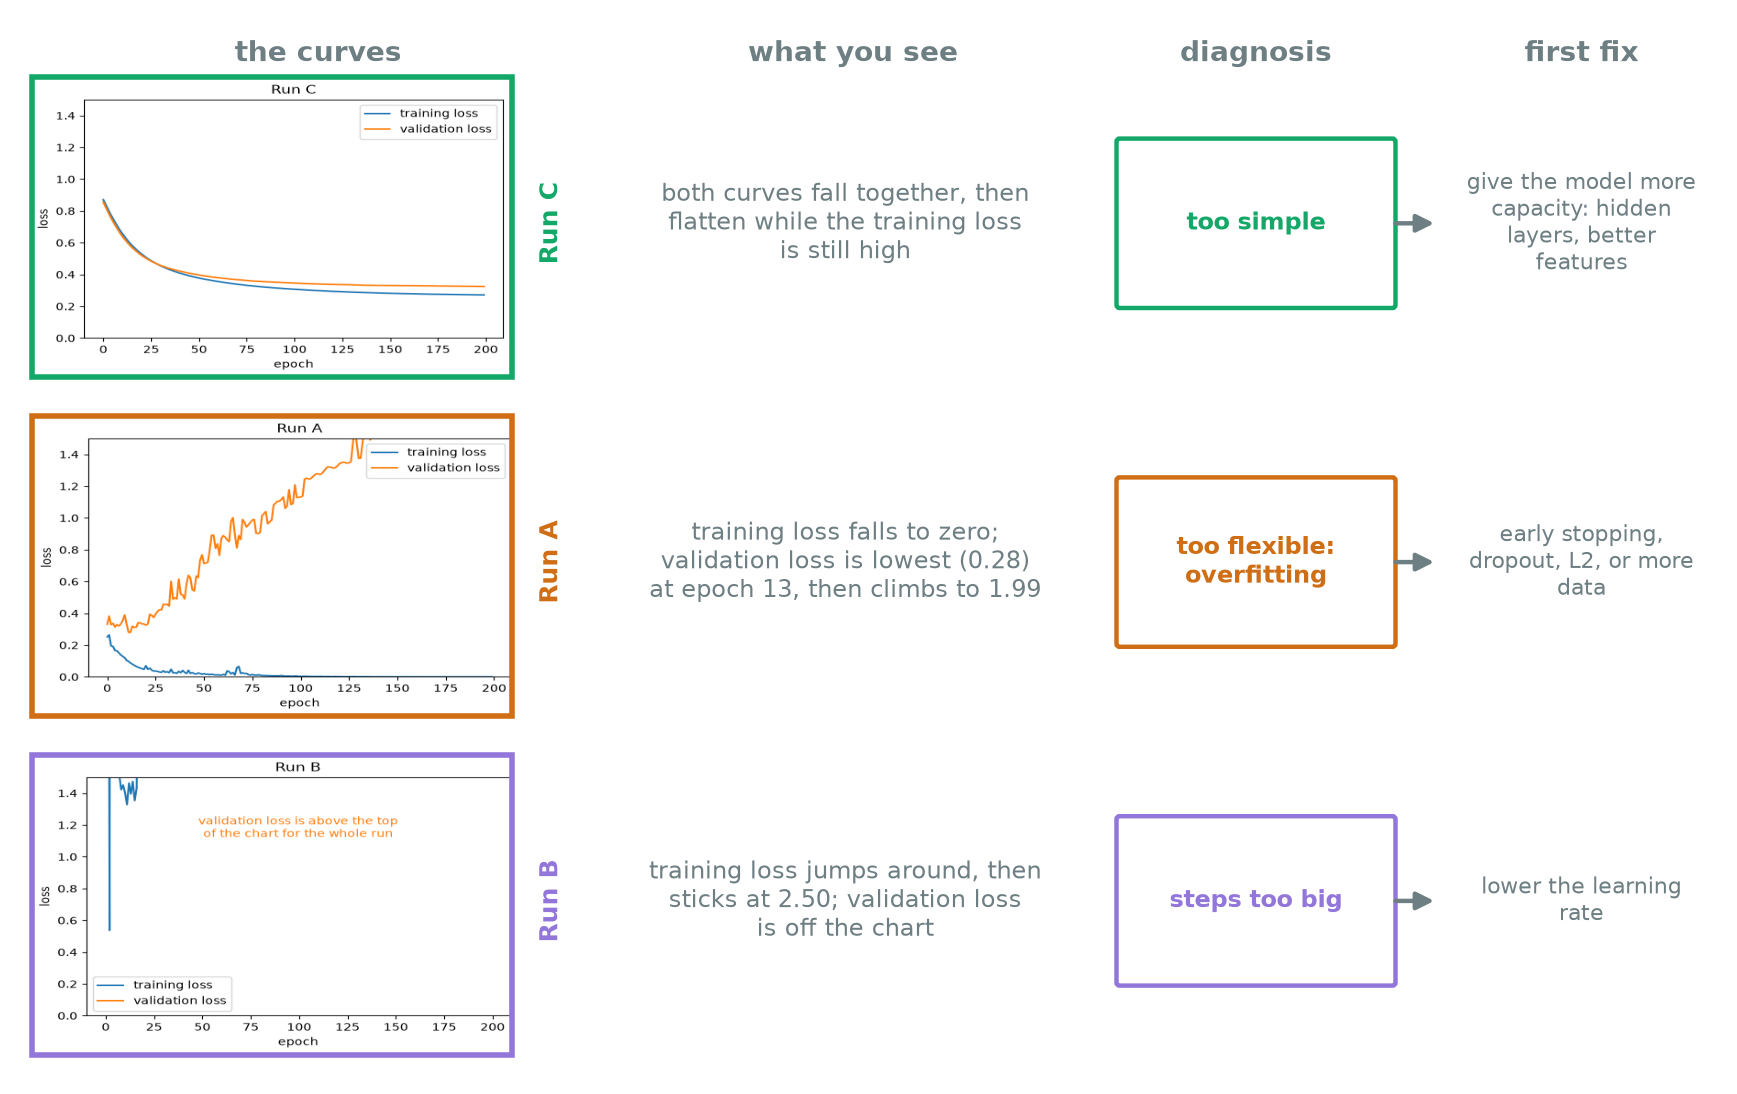

*Figure P.3 — Reading training curves (from the basic course, Session 7). Too simple: both losses level off high together. Too flexible: training loss falls to zero while validation loss turns and climbs. Steps too big: the training loss jumps around or gets stuck.*

The second pattern is the usual one. In the run behind the middle row, a network with 66,817 weights was trained on 80 points (basic course, Session 7). Its training loss fell to 0.000, while its validation loss was lowest at epoch 13 (0.28) and then climbed to 1.99 by epoch 200. Every improvement on the training points after epoch 13 made its predictions on new points worse.

The fixes were tried one at a time. **Early stopping** keeps the weights from the epoch with the lowest validation loss; it was the cheapest fix and the best one there (0.280 against 1.992). **Dropout** switches off a random half of the hidden units at every step, and an **L2 penalty** adds the size of the weights to the loss. Two habits that catch problems the curves hide:

- Before anything else, check that the network can learn about 10 training examples by heart. If it can't, the bug is in the code.
- Look at accuracy or at real predictions, not only the loss. In one real bug, a softmax taken across the examples of a batch instead of across the classes kept the loss falling while the model answered 0 for every example.

## 8. Images: a filter slid over the picture

An image is a grid of numbers, and its layout carries most of its meaning. A dense network flattens the grid into a row and gives every pixel its own weights. A **convolutional network (CNN)** instead slides small **filters**, 3×3 grids of weights, over the whole image, using the same weights at every position. Here are two networks for 28×28 handwritten digits, one of each kind, with their weights counted.

In [7]:
dense = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
cnn = nn.Sequential(nn.Conv2d(1, 16, 3), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(16, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Flatten(), nn.Linear(800, 10))
count = lambda m: sum(p.numel() for p in m.parameters())
x = torch.zeros(1, 1, 28, 28)                                  # one blank image, to follow the shapes
for layer in cnn:
    x = layer(x); print(f"{type(layer).__name__:10s} output {str(tuple(x.shape[1:])):13s} parameters {count(layer):>6,}")
print(f"CNN total {count(cnn):,};  dense network total {count(dense):,}")

Conv2d     output (16, 26, 26)  parameters    160
ReLU       output (16, 26, 26)  parameters      0
MaxPool2d  output (16, 13, 13)  parameters      0
Conv2d     output (32, 11, 11)  parameters  4,640
ReLU       output (32, 11, 11)  parameters      0
MaxPool2d  output (32, 5, 5)    parameters      0
Flatten    output (800,)        parameters      0
Linear     output (10,)         parameters  8,010
CNN total 12,810;  dense network total 101,770


The first convolution's 16 filters need 160 numbers (16 × 9 weights + 16 biases), and the whole CNN needs 12,810. The dense network's first layer alone needs 784 × 128 + 128 = 100,480, and the whole network 101,770, about eight times as many. The CNN is smaller because it uses the same filters at every position of the image.

| digits shifted, pixels (basic course, Session 8) | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| dense network | 0.931 | 0.883 | 0.683 | 0.445 | 0.245 |
| CNN | 0.973 | 0.963 | 0.914 | 0.746 | 0.557 |

Trained on the MNIST digits and tested on digits moved a few pixels to the right, the dense network fell apart much faster: at 2 pixels it lost 24.8 points and the CNN 5.9. The CNN's filters look for the same stroke wherever it appears. It is still not immune; that remaining gap is closed by training on shifted images.

The design of a network builds in what we believe about the data. Attention, at the end of this notebook, builds in something different: that any position may need any other.

## 9. Reusing a trained network

Few projects have millions of labelled images, so the usual start is a network someone else has trained. Three ways of getting a flower classifier from 1,400 photos, with everything else held fixed:

| strategy (basic course, Session 9) | trainable parameters | test accuracy |
|---|---:|---:|
| from scratch | 2,230,277 | 0.710 |
| pretrained backbone, frozen; only the new head trained | 6,405 | 0.850 |
| pretrained, then the last blocks fine-tuned | 1,532,485 | 0.883 |

A pretrained network is a **backbone** that turns an input into useful features, plus a small **head** for the task. Starting from weights learned on a million ImageNet photos was worth 14 points while training 348 times fewer weights. **Fine-tuning**, which unfreezes part of the backbone with a small learning rate after the head has been trained, added about 3 more. This course does the same with language models: Session 6 turns a pretrained model into an assistant, and Session 7 fine-tunes one with LoRA, which trains a small number of added weights and leaves the rest frozen. Session 13 comes back to the same flower photos with a vision transformer.

---

# Part 3 — Text, order and memory, and the step after it

## 10. Tokens, ids and vectors

A model can't read letters. Text is cut into **tokens**, each token gets a whole number, its **id**, and each id picks one row of a table of learned numbers, its **embedding**.

In [8]:
sentence = "The movie was not good at all."
words = sentence.lower().replace(".", "").split()
vocabulary = {w: i for i, w in enumerate(sorted(set(words)))}
ids = torch.tensor([vocabulary[w] for w in words])
print("tokens:", words)
print("ids:   ", ids.tolist(), " from", vocabulary)

set_seed(0)
embedding = nn.Embedding(len(vocabulary), 4)                  # one row of 4 learned numbers per word
vectors = embedding(ids)
one_hot = nn.functional.one_hot(ids, len(vocabulary)).float()
print("vectors:", tuple(vectors.shape), "  largest difference from one-hot @ table:", (vectors - one_hot @ embedding.weight).abs().max().item())

tokens: ['the', 'movie', 'was', 'not', 'good', 'at', 'all']
ids:    [5, 3, 6, 4, 2, 1, 0]  from {'all': 0, 'at': 1, 'good': 2, 'movie': 3, 'not': 4, 'the': 5, 'was': 6}
vectors: (7, 4)   largest difference from one-hot @ table: 0.0


The seven words get ids 5, 3, 6, 4, 2, 1, 0 (this vocabulary is sorted alphabetically). The ids are labels, not quantities: id 5 is not "more" than id 3. Each id picks a row of the embedding table, so the sentence becomes 7 vectors of 4 numbers. Picking a row is the same as multiplying a **one-hot** vector (all zeros except a 1 at the id) by the table, and the largest difference between the two results is 0.0. The table's numbers are weights like any others, learned in training. In a small LSTM for movie reviews, a table of 20,000 words × 32 numbers held 640,000 of its 648,481 parameters (basic course, Session 10). Session 0 of this course shows how GPT-2 learns its vocabulary of 50,257 pieces of words, and how much of the model its embedding table takes up.

On a real task, classifying 25,000 IMDB movie reviews as positive or negative after training on 10,000, three models compare like this:

| model (basic course, Session 10) | test accuracy |
|---|---:|
| word counts (TF-IDF) and logistic regression | 0.877 |
| the same with word pairs ("not good") as extra features | 0.884 |
| an LSTM that reads each review in order | 0.825 |

A **bag of words** keeps which words occur and how often, and throws the order away, so "not good" and "good, not" look the same. Word pairs put a little order back: the pair "not good" got a weight of −0.94. The LSTM can use all of the order, but on 10,000 reviews it overfitted after two epochs and lost to the word counts. The word vectors it learned put "great" next to "wonderful", "favorite" and "excellent", and "terrible" next to "mess", "bad" and "cheap": words used alike end up near each other.

## 11. Reading in order: the LSTM

An **LSTM** (long short-term memory; Sepp Hochreiter and Jürgen Schmidhuber, 1997) reads a sequence one token at a time. It keeps a **memory**, a vector of fixed size, and updates it after every token: gates decide how much of the old memory to keep, how much of the new token to write in, and what to show. After the last token, the memory goes to the output layer.

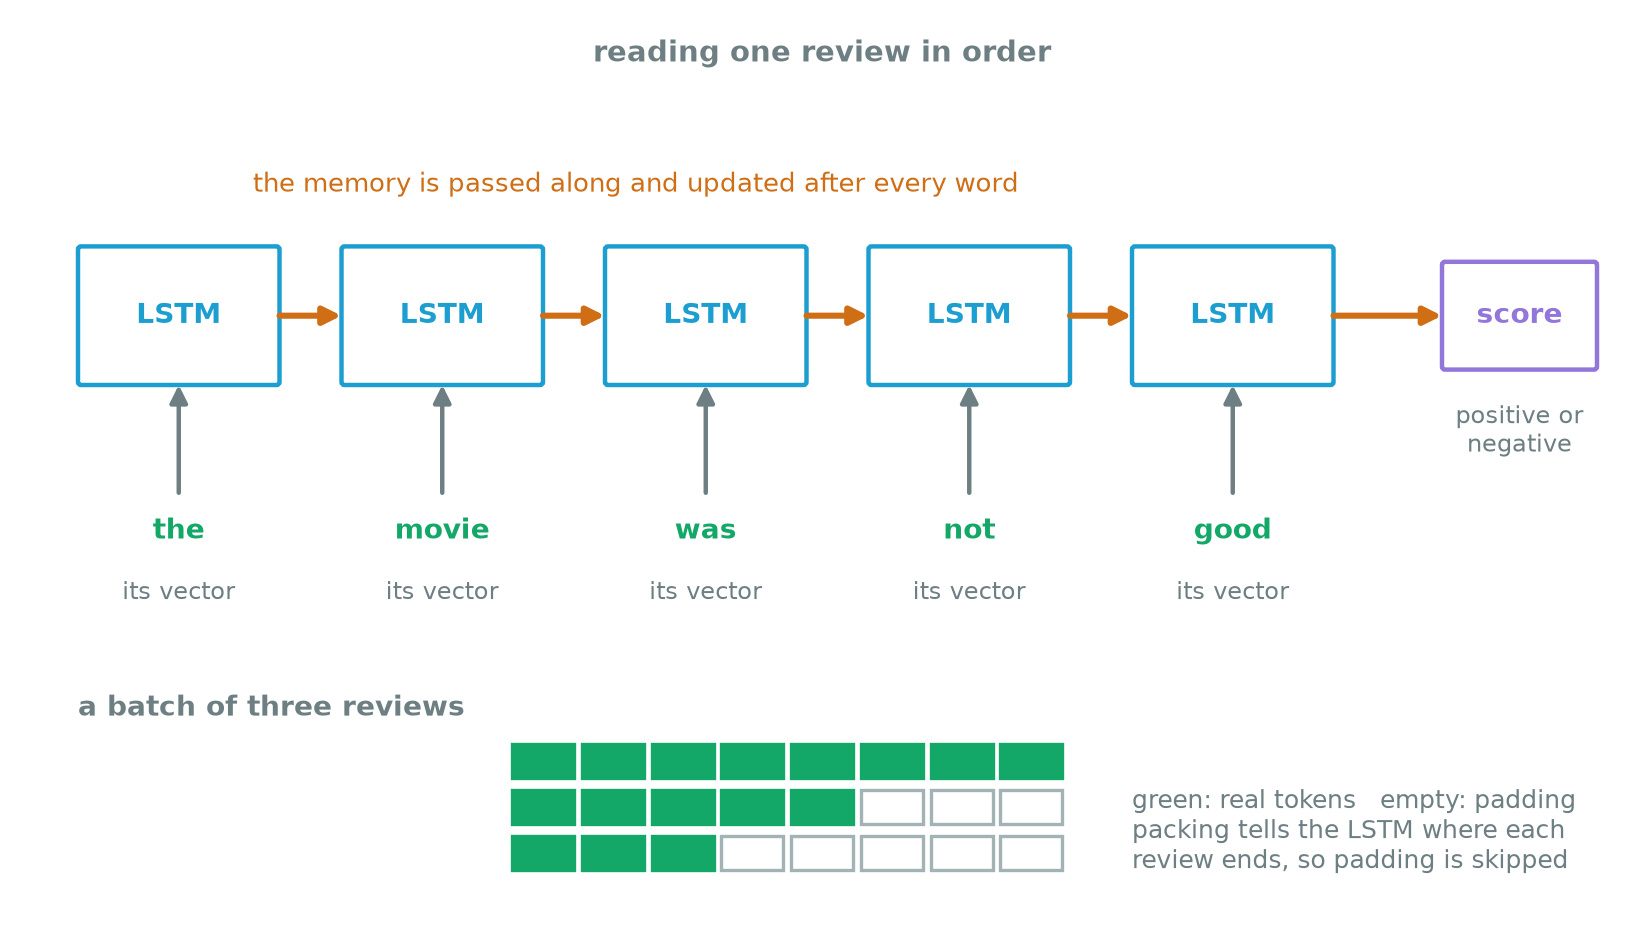

*Figure P.4 — An LSTM reads one token at a time and passes its memory along; the last memory feeds the output (from the basic course, Session 10).*

To see what reading in order buys, we use a task where order is the whole point. Each example is 8 words: fillers, one opinion word (`good`, `great`, `fun`, `lovely` or `bad`, `dull`, `awful`, `boring`) and exactly one `not`. Half the time the `not` comes directly before the opinion word and flips it; otherwise it is somewhere else and changes nothing. Because every example contains one `not`, counting words can't tell which case it is.

The next cell holds the helpers for this section and the next two: a generator of fresh batches, a training loop (the loop from section 6, on a new batch at every step), and an LSTM classifier with 32 numbers of memory. Presenters skip it on screen.

In [9]:
def train(build, make_batch, steps, lr=3e-3, seed=0):
    """Build a model with a fixed seed and train it with Adam, on a fresh batch of 256 examples at every step."""
    set_seed(seed); model = build().to(DEVICE)
    g = torch.Generator().manual_seed(seed + 1)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        x, y = make_batch(256, g)
        loss = nn.functional.cross_entropy(model(x.to(DEVICE)), y.to(DEVICE))
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    return model.eval()

@torch.no_grad()
def accuracy(model, x, y):
    return (model(x.to(DEVICE)).argmax(-1).cpu() == y).float().mean().item()

def previous(x, start):
    """The token just before each position (start for the first)."""
    return torch.cat([torch.full_like(x[:, :1], start), x[:, :-1]], 1)

class LSTMReader(nn.Module):
    """Embedding, an LSTM with `memory` numbers, and a linear layer on the memory after the last token.
    note=True also adds to each token a learned vector for the token just before it (used in section 13)."""
    def __init__(self, vocab, classes, memory=32, note=False):
        super().__init__()
        self.embed = nn.Embedding(vocab, 32)
        self.note = nn.Embedding(vocab, 32) if note else None
        self.lstm = nn.LSTM(32, memory, batch_first=True)
        self.out = nn.Linear(memory, classes)
    def forward(self, x):
        z = self.embed(x)
        if self.note is not None: z = z + self.note(previous(x, self.note.num_embeddings - 1))
        h, _ = self.lstm(z)
        return self.out(h[:, -1])

OPINION = ["good", "great", "fun", "lovely", "bad", "dull", "awful", "boring"]       # 0-3 positive, 4-7 negative
FILLER = ["the", "film", "was", "plot", "acting", "and", "it", "a", "story", "really", "quite", "cast"]
WORDS = OPINION + FILLER + ["not"]; NOT, LENGTH = len(WORDS) - 1, 8

def negation_batch(n, g):
    x = torch.randint(len(OPINION), NOT, (n, LENGTH), generator=g)                  # fillers everywhere
    at = torch.randint(1, LENGTH, (n,), generator=g)                                  # where the opinion word goes
    word = torch.randint(0, len(OPINION), (n,), generator=g)
    flipped = torch.rand(n, generator=g) < 0.5
    elsewhere = torch.rand(n, LENGTH, generator=g)
    elsewhere[torch.arange(n), at] = -1; elsewhere[torch.arange(n), at - 1] = -1     # not on the word, not just before it
    x[torch.arange(n), torch.where(flipped, at - 1, elsewhere.argmax(1))] = NOT
    x[torch.arange(n), at] = word
    return x, ((word < 4) ^ flipped).long()                                           # 1 = positive

x_neg, y_neg = negation_batch(4000, torch.Generator().manual_seed(100))
for i in range(3):
    print(" ".join(WORDS[t] for t in x_neg[i]), "->", ["negative", "positive"][y_neg[i]])

acting acting not cast a lovely the quite -> positive
not story quite and was great it quite -> positive
and the the cast not lovely the it -> negative


> **Pause:** a word-count model sees one `not` in every example, plus the opinion word. Trained on 20,000 examples, what test accuracy will it reach? And the LSTM?
>
> - **A.** Both near 1.0: the task is easy.
> - **B.** Word counts about 0.5, the LSTM near 1.0.
> - **C.** Both about 0.5: the `not` is too hard to place.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**B.** Word counts score 0.487, no better than guessing, and the LSTM 1.000.

</details>

In [10]:
x_tr, y_tr = negation_batch(20000, torch.Generator().manual_seed(101))
counts = lambda x: nn.functional.one_hot(x, len(WORDS)).sum(1).numpy()                     # a bag of words: counts, no order
bag = LogisticRegression(max_iter=2000).fit(counts(x_tr), y_tr)
lstm_neg = train(lambda: LSTMReader(len(WORDS), 2), negation_batch, steps=600)
print(f"word counts and logistic regression: test accuracy {bag.score(counts(x_neg), y_neg):.3f}")
print(f"LSTM:                                test accuracy {accuracy(lstm_neg, x_neg, y_neg):.3f}")

word counts and logistic regression: test accuracy 0.487
LSTM:                                test accuracy 1.000


Word counts score 0.487 on 4,000 new examples. They see the opinion word and one `not` in every example, and they can't tell whether the `not` flips the opinion. The LSTM reads in order and scores 1.000 after 600 training steps.

Word pairs would also solve this task, because the `not` that flips is always directly before its word. They can't handle a `not` further away, and an LSTM can in principle. On the real reviews above, the LSTM still lost to word counts: 10,000 reviews were too few for it to learn what the counts get for free.

## 12. A memory of fixed size

Everything the LSTM has read has to fit in its memory, 32 numbers here, until the moment it is needed. A task that asks it to hold many things at once shows the limit.

In the **recall** task, each example is a list of key–value pairs, then a `?` and one of the keys. The answer is that key's value. Keys are the letters A to T, values the digits 0 to 9, and the pairs are new random ones in every example, so nothing can be learned about particular letters: the model has to read the list and look the key up. With 1 pair it only has to hold one value; with 16 it has to hold all 16, because it doesn't know which key will be asked until the end. Guessing scores 0.1.

In [11]:
N_KEY, N_VALUE = 20, 10
ASK = N_KEY + N_VALUE; RECALL_VOCAB = ASK + 1                    # ids: keys 0-19, values 20-29, then "?"
NAMES = [chr(65 + i) for i in range(N_KEY)] + [str(i) for i in range(N_VALUE)] + ["?"]

def recall_batch(n, g, pairs):
    keys = torch.rand(n, N_KEY, generator=g).argsort(1)[:, :pairs]                   # distinct keys
    values = torch.randint(0, N_VALUE, (n, pairs), generator=g)
    asked = torch.randint(0, pairs, (n,), generator=g)
    rows = torch.arange(n)
    x = torch.cat([torch.stack([keys, values + N_KEY], 2).reshape(n, 2 * pairs),
                   torch.full((n, 1), ASK), keys[rows, asked][:, None]], 1)
    return x, values[rows, asked]

x_ex, y_ex = recall_batch(1, torch.Generator().manual_seed(20), pairs=4)
print(" ".join(NAMES[t] for t in x_ex[0]), "  answer:", y_ex.item())

T 2 K 5 H 6 B 8 ? H   answer: 6


We train the same LSTM for 1,500 steps on each list length and score it on 2,000 new lists.

> **Pause:** with 1 pair the LSTM gets every answer right. What happens as the list grows to 16 pairs?
>
> - **A.** Nothing much: 32 numbers are plenty for 16 digits.
> - **B.** A slow, small decline.
> - **C.** A steep fall, close to guessing by 16 pairs.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**C.** The LSTM scores 1.000 with 1 pair, 0.923 with 2, 0.387 with 4 and 0.213 with 16, where guessing scores 0.1.

</details>

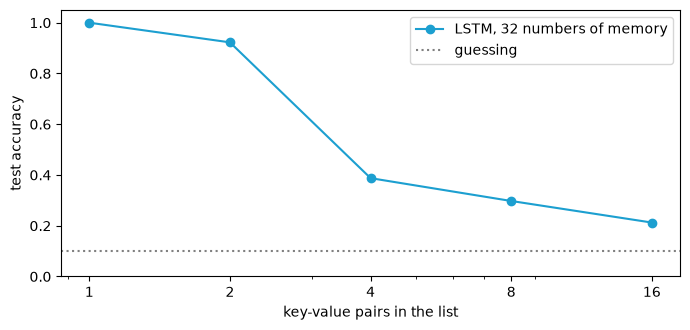

test accuracy by number of pairs: {1: 1.0, 2: 0.923, 4: 0.387, 8: 0.298, 16: 0.213}


In [12]:
# Figure P.5: the LSTM's recall accuracy as the list grows
list_lengths, lstm_recall = [1, 2, 4, 8, 16], {}
for pairs in list_lengths:
    batch = lambda n, g, pairs=pairs: recall_batch(n, g, pairs)
    x_te, y_te = recall_batch(2000, torch.Generator().manual_seed(200), pairs)
    lstm_recall[pairs] = accuracy(train(lambda: LSTMReader(RECALL_VOCAB, N_VALUE), batch, steps=1500), x_te, y_te)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(list_lengths, list(lstm_recall.values()), "o-", color="#1C9FD0", label="LSTM, 32 numbers of memory")
ax.axhline(0.1, color="gray", ls=":", label="guessing")
ax.set(xscale="log", xticks=list_lengths, xticklabels=list_lengths, xlabel="key-value pairs in the list", ylabel="test accuracy", ylim=(0, 1.05))
ax.legend(); plt.tight_layout(); plt.show()
print("test accuracy by number of pairs:", {k: round(v, 3) for k, v in lstm_recall.items()})

*Figure P.5 — The LSTM's test accuracy on the recall task, by the number of key–value pairs in each list, after 1,500 training steps on 256 new lists each. Guessing scores 0.1.*

With one pair the LSTM is perfect. With 2 pairs it scores 0.923, with 4 pairs 0.387, with 8 pairs 0.298 and with 16 pairs 0.213, a little above guessing. This is not overfitting: every training list is new, and the test lists come from the same generator. The LSTM has to write each pair into its 32 numbers as it reads and keep all of them until the question, and it can't do that for more than two or three pairs. A larger memory would hold more, but it would still have a fixed size, while the text it has to hold can be of any length.

The LSTM has a second limit: it reads one token after another, so step 10 can't start until step 9 is finished. Session 0 of this course shows a transformer scoring every position of a text in a single pass.

## 13. Attention: look back instead of remembering

**Attention** removes the bottleneck. Instead of carrying everything in one memory, the position that needs an answer looks back at every earlier position directly and takes what it needs from the right one. It works with three vectors that every token computes from its own vector:

- a **query**: what this token is looking for;
- a **key**: what this token can be found by;
- a **value**: what it hands over when it is chosen.

The query is compared with every key by a dot product, the scores go through a softmax to become **weights** that add up to 1, and the output is the weighted mix of the values.

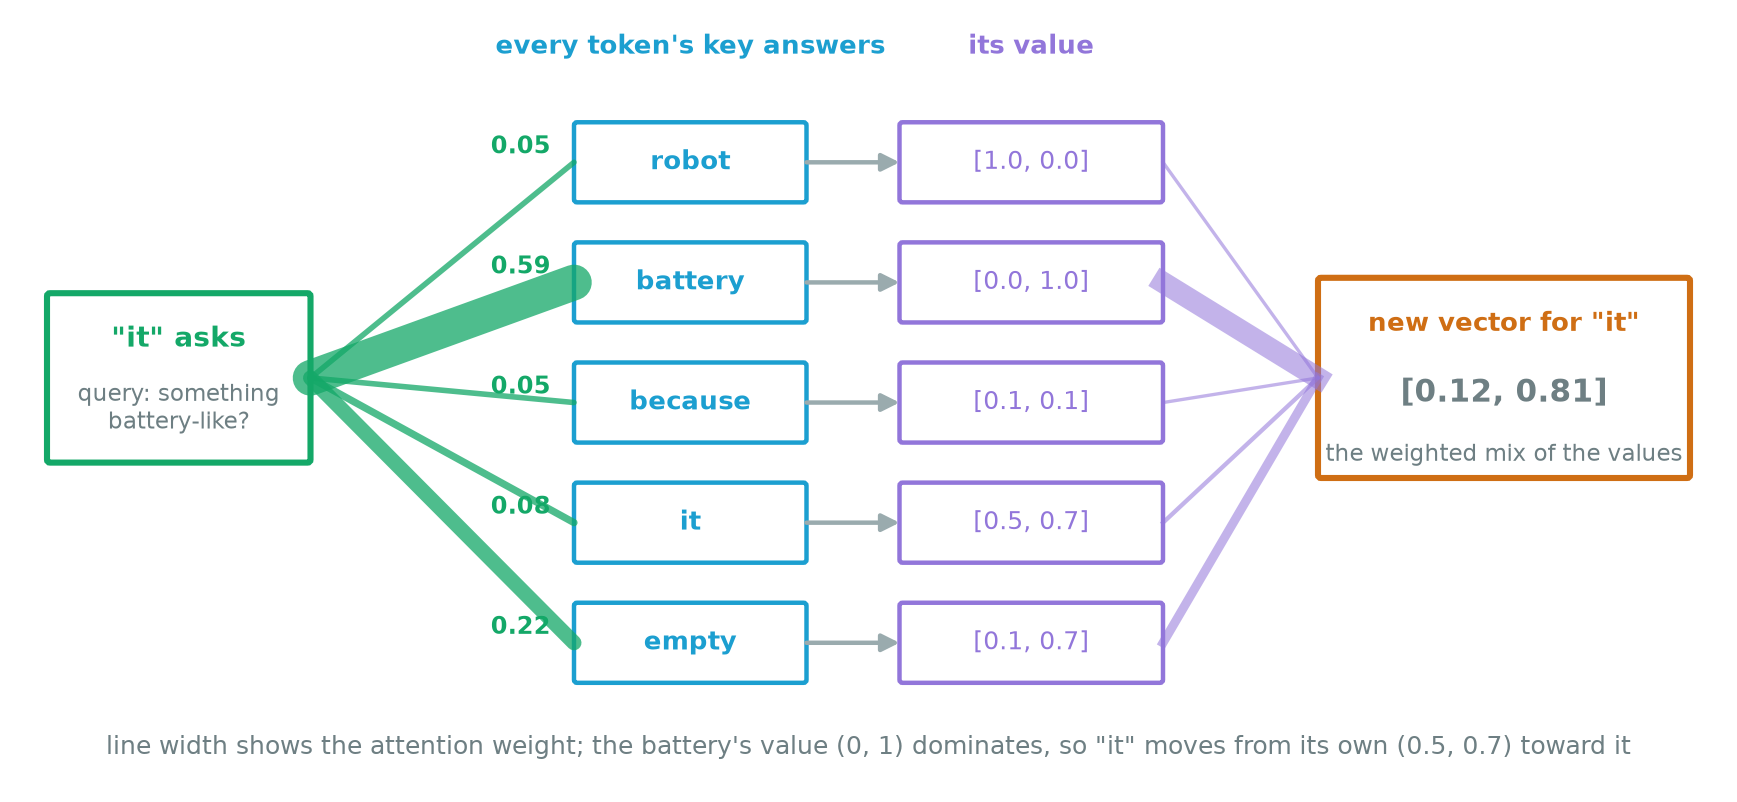

*Figure P.6 — Attention for the word "it" in "the robot put the battery in the device because it was empty" (from the basic course, Session 11, with numbers chosen by hand). The query of "it" is matched against every key; the weights, drawn as line widths, go mostly to battery (0.59); the new vector for "it" is the weighted mix of the values.*

For the recall task, the answer sits at the position just after the asked key. So we give each position one extra piece of information: a note of the token just before it. A value digit then carries "my key was K". In a transformer this note is written by a **previous-token head** in an early layer, and Session 1 of this course finds one in GPT-2.

With the note, attention can be written by hand. The query at the last position is the asked key; each position's key is its note; each position's value is its own token. All three are one-hot vectors, so the dot product is 1 where the note matches the asked key and 0 elsewhere. We multiply the scores by 10 so the softmax picks clearly.

In [13]:
x = x_ex[0]
note = previous(x_ex, ASK)[0]
one_hot = lambda t: nn.functional.one_hot(t, RECALL_VOCAB).float()
query, keys, values = one_hot(x[-1]), one_hot(note), one_hot(x)
weights = (keys @ query * 10).softmax(0)
answer = int((weights @ values).argmax())
print(pd.DataFrame({"token": [NAMES[t] for t in x], "note: token before": ["(start)"] + [NAMES[t] for t in note[1:]],
                    "weight": weights.numpy().round(3)}).T.to_string(header=False))
print(f"\nasked: {NAMES[x[-1]]}   attention's answer: {NAMES[answer]}   right answer: {y_ex.item()}")

token                     T    2    K    5    H    6    B    8    ?    H
note: token before  (start)    T    2    K    5    H    6    B    8    ?
weight                  0.0  0.0  0.0  0.0  0.0  1.0  0.0  0.0  0.0  0.0

asked: H   attention's answer: 6   right answer: 6


The asked key is H. The only position whose note is H is the value 6, just after H in the list, so its score is 10 and every other score is 0. It gets a weight of 1.0 after rounding, and the weighted mix of the values is the value 6, the right answer.

Nothing in this lookup depends on how long the list is: with 16 pairs or 1,000, it is one comparison per position. And nothing has to be remembered, because the list is still there to be read when the question comes.

That was written by hand. The model below learns its queries, keys and values: each position's vector is a learned embedding of its token plus a learned embedding of its note, and three learned matrices turn it into a query, a key and a value. Only the last position asks. Its scores are divided by $\sqrt{d}$, the size of the vectors, as in every transformer (Session 1 measures why). We train it on lists of 16 pairs, where the LSTM scored 0.213, and give the LSTM the same note for a fair comparison.

In [14]:
class AttentionReader(nn.Module):
    """One attention head: the last position's query against every position's key; the output is the weighted mix of values."""
    def __init__(self, vocab, classes, d=32):
        super().__init__()
        self.embed, self.note = nn.Embedding(vocab, d), nn.Embedding(vocab, d)
        self.query, self.key, self.value = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d)
        self.out = nn.Linear(d, classes)
    def forward(self, x, return_weights=False):
        z = self.embed(x) + self.note(previous(x, self.note.num_embeddings - 1))
        q, k, v = self.query(z[:, -1:]), self.key(z), self.value(z)
        weights = (q @ k.transpose(1, 2) / math.sqrt(k.shape[-1])).softmax(-1)          # (batch, 1, positions)
        out = self.out((weights @ v)[:, 0])
        return (out, weights[:, 0]) if return_weights else out

batch16 = lambda n, g: recall_batch(n, g, 16)
x_te, y_te = recall_batch(2000, torch.Generator().manual_seed(200), 16)
attention = train(lambda: AttentionReader(RECALL_VOCAB, N_VALUE), batch16, steps=1500)
lstm_note = train(lambda: LSTMReader(RECALL_VOCAB, N_VALUE, note=True), batch16, steps=1500)
print(f"16 pairs, test accuracy:  attention {accuracy(attention, x_te, y_te):.3f}   "
      f"LSTM with the same note {accuracy(lstm_note, x_te, y_te):.3f}   LSTM {lstm_recall[16]:.3f}")
print(f"parameters: attention {sum(p.numel() for p in attention.parameters()):,}   LSTM with the note {sum(p.numel() for p in lstm_note.parameters()):,}")

16 pairs, test accuracy:  attention 1.000   LSTM with the same note 0.215   LSTM 0.213
parameters: attention 5,482   LSTM with the note 10,762


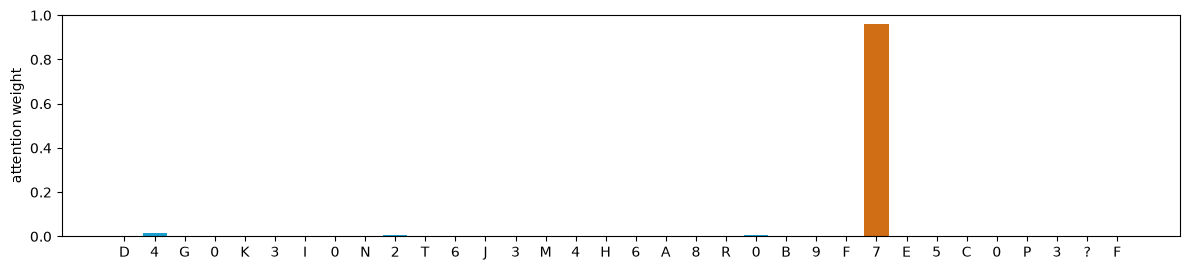

asked: F; largest weight 0.961 on position 26 (7), just after the key F;  answer 7, right answer 7


In [15]:
# Figure P.7: where the trained attention head looks, on one list of 16 pairs
where_asked = (x_te[:, :-2] == x_te[:, -1:]).float().argmax(1)                    # position of the asked key in each list
i = int((where_asked >= 12).nonzero()[0])                                           # the first list where it is in the middle or later
with torch.no_grad():
    logits, w = attention(x_te[i:i + 1].to(DEVICE), return_weights=True)
w, x0 = w[0].cpu().numpy(), x_te[i]
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.bar(range(len(x0)), w, color=["#CF6E14" if i == w.argmax() else "#1C9FD0" for i in range(len(x0))])
ax.set(xticks=range(len(x0)), xticklabels=[NAMES[t] for t in x0], ylabel="attention weight", ylim=(0, 1))
plt.tight_layout(); plt.show()
print(f"asked: {NAMES[x0[-1]]}; largest weight {w.max():.3f} on position {w.argmax() + 1} ({NAMES[x0[w.argmax()]]}), "
      f"just after the key {NAMES[x0[w.argmax() - 1]]};  answer {NAMES[N_KEY + int(logits.argmax())]}, right answer {y_te[i].item()}")

*Figure P.7 — The trained head's attention weights from the last position, the asked key F, over one list of 16 pairs. Almost all the weight (0.961) is on the value 7, just after F, thirteenth of the 16 pairs.*

The single trained head scores 1.000 on lists of 16 pairs. The LSTM with the same note scores 0.215, no better than without it (0.213): the note tells it which key each value belongs to, but it still has to hold all 16 pairs in 32 numbers. The attention model also has about half as many parameters (5,482 against 10,762). On the list in the figure it puts 0.961 of its weight on the value after the asked key, 26 positions into the list.

This lookup has a name. An **induction head** finds the earlier occurrence of the current token and copies what came after it. Session 1 of this course finds such heads in GPT-2, together with the previous-token head that writes the note, and tests whether the model needs them.

Three more things about attention that this course relies on:

- **Every position asks.** In a language model, every token has a query and looks back, not only the last. A **causal mask** stops each token from reading the tokens after it, so the model can't see the word it is trying to predict; the masked weights are zero.
- **Many heads.** A **head** is one set of query, key and value matrices. A transformer layer runs several in parallel, each free to look for something different: GPT-2 has 12 heads in each of its 12 layers. Heads in one layer can use what heads in earlier layers wrote, which is how the note in this section gets written.
- **No order of its own.** Attention compares vectors, not places, so on its own it treats the input as a set. Transformers add information about position to each token's vector; Session 2 covers three ways of doing it.

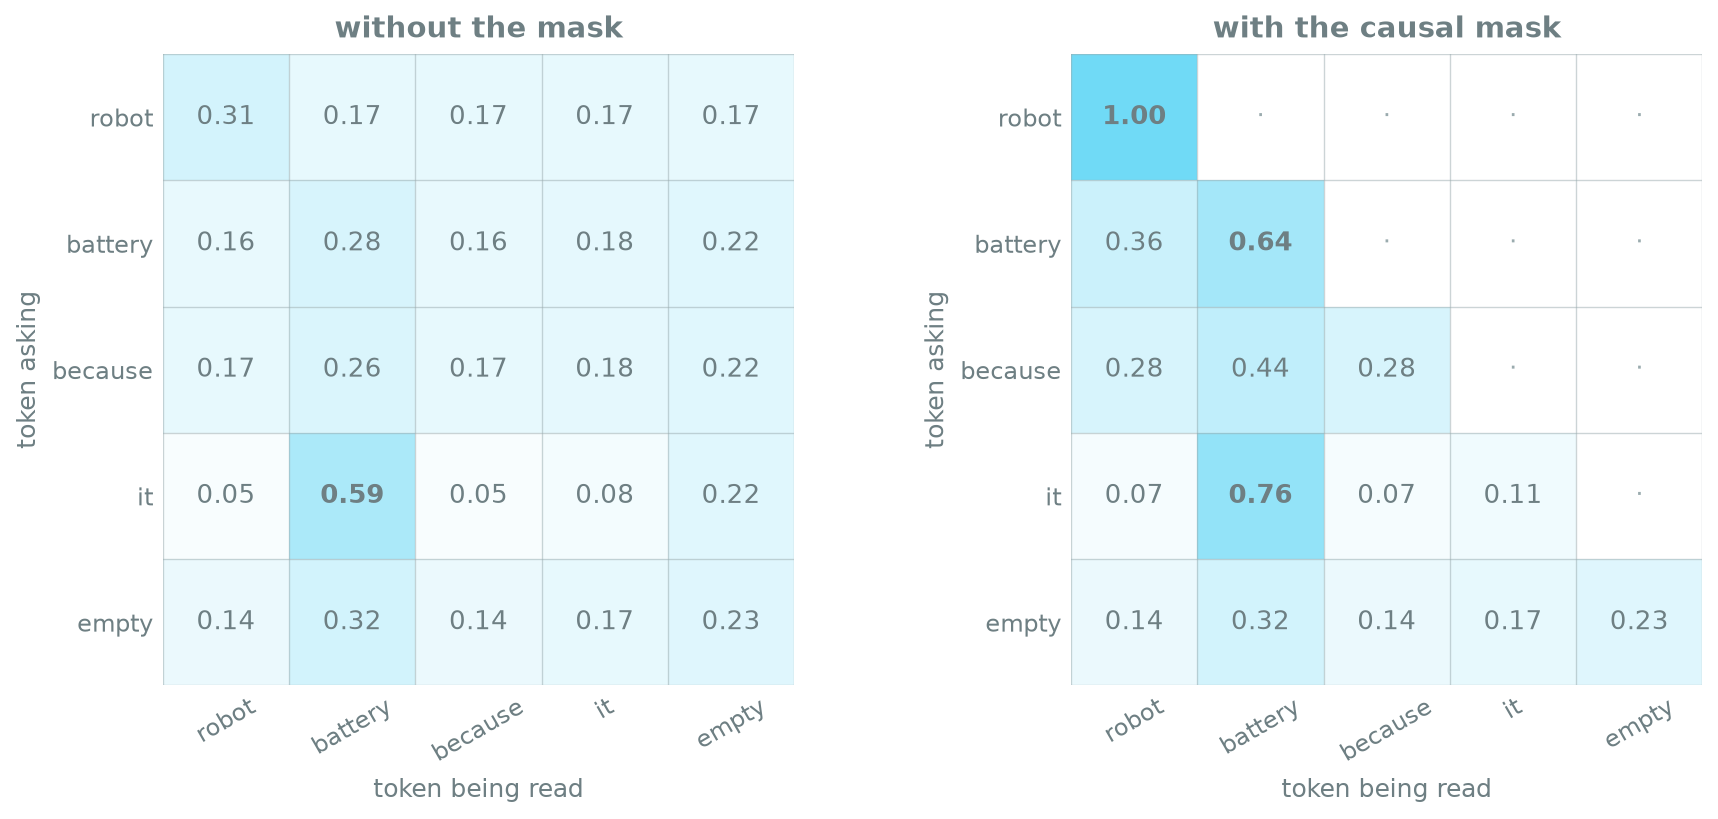

*Figure P.8 — The causal mask (from the basic course, Session 11). Without it (left) every token reads every other; with it (right) each token reads only itself and the tokens before it, and the cells above the diagonal are zero.*

## 14. Where this course starts

The **transformer** (Vaswani and colleagues, 2017) stacks layers of attention heads with small networks in between. GPT-2, BERT and the assistants of this course's later sessions are all transformers. The table shows where each idea from this notebook comes back.

| From this notebook | Where it comes back |
|---|---|
| tokens, ids and embeddings (section 10) | Session 0: how GPT-2's vocabulary is learned, and its embedding table |
| logits, softmax, cross-entropy in bits (section 6) | Session 0: what each token costs the model; Session 3: the training loss of a small GPT |
| attention, the previous-token note, masks and heads (section 13) | Session 1: attention written out for GPT-2, induction heads; Session 4: what the mask lets each layout read |
| a network built from layers, with positions added (section 13) | Session 2: the transformer block, the residual stream, positions |
| the training loop and its curves (sections 6 and 7) | Session 3: training a GPT, warm-up, norm placement |
| pretraining and fine-tuning (section 9) | Sessions 6 and 7: from a base model to an assistant, LoRA |
| validation, test once, noise between runs (sections 2 and 4) | Sessions 10 and 11: evaluating models and experiments you can believe |
| CNNs and the flower photos (sections 8 and 9) | Session 13: vision transformers and CLIP |

Session 1 starts directly from the attention formula with GPT-2's real sizes. If the query, key and value of section 13 are clear, it will read as the same computation at a larger scale.

## What to take away

- An experiment is split, baseline, fit, evaluate once, read the errors. Every preprocessing step is fitted on the training rows, and a score means little without a baseline and an idea of how much it moves between splits.
- Training is one loop: loss, gradient, step. Logits become probabilities through a softmax, and cross-entropy, in nats or bits, is the cost of the right answer.
- Read training and validation loss together: rising validation loss under falling training loss is overfitting.
- Text becomes tokens, ids and vectors. An LSTM reads in order but carries everything in a memory of fixed size: on the recall task it fell from 1.000 with one pair to 0.213 with sixteen.
- Attention lets a position look back at every earlier one through queries, keys and values. One trained head scored 1.000 on sixteen pairs, where the LSTM given the same help scored 0.215.